# 03. Entrenamiento y comparación temporal de modelos
Se predice si un vuelo llegará con **al menos 15 minutos de retraso**, dos horas antes de su salida programada. Se entrenan realmente Dummy, regresión logística, Random Forest e HistGradientBoosting.

Se utiliza únicamente B: las 26 características de programación y clima histórico ya preparadas. Esto permite comparar las familias con la misma información sin multiplicar los ajustes. El clima sigue teniendo disponibilidad estimada.


## 1. Datos y configuración
Se reconstruyen las características desde las tablas originales. No se leen métricas ni predicciones de entrenamientos anteriores. El umbral es 0,5 y la semilla es 42.


In [1]:
import sys
from pathlib import Path
sys.dont_write_bytecode = True
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz / 'src'))
sns.set_theme(style='whitegrid')

import time
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
from threadpoolctl import threadpool_limits
from features import cargar_features, FEATURES_B, NUMERICAS_A, EXTRA_CLIMA, CATEGORICAS
from data import TARGET_COL, LEAKAGE_COLS
from metricas import calcular_metricas
SEED, HILOS, UMBRAL = 42, 3, 0.5
MESES_VALIDACION, MARGEN_HORAS = [5, 6, 7, 8, 9, 10], 72
datos = cargar_features()
etiquetados = datos.loc[datos[TARGET_COL].notna()].copy()
etiquetados[TARGET_COL] = etiquetados[TARGET_COL].astype(int)
assert datos['month'].between(1, 11).all()
assert not set(FEATURES_B).intersection(LEAKAGE_COLS + [TARGET_COL, 'plane_year', 'seats', 'engine', 'tailnum'])
display(pd.DataFrame({'mes': etiquetados['month'].value_counts().sort_index().index,
                     'vuelos_etiquetados': etiquetados['month'].value_counts().sort_index().values}))


C:\Users\Rodrigo D SantaMaria\AppData\Local\Programs\Python\Python313\Lib\site-packages\nycflights13\__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename as _rf


,mes,vuelos_etiquetados
0,1,26398
1,2,23611
2,3,27902
3,4,27564
4,5,28128
5,6,27075
6,7,28293
7,8,28756
8,9,27010
9,10,28618


Las filas sin `arr_delay` observado no se consideran negativas: se excluyen del aprendizaje supervisado. Los atributos de aeronaves, retrasos reales y clima de la hora programada quedan fuera de los predictores.

## 2. Separación temporal
Se mantienen ventanas expansivas: enero–abril → mayo, y así sucesivamente hasta enero–septiembre → octubre. Se excluyen las últimas 72 horas anteriores al corte y las etiquetas cuya disponibilidad estimada no sea anterior al inicio del mes.

La etiqueta se estima disponible en salida programada + retraso positivo de salida + tiempo de vuelo + 24 horas. Estos datos reales determinan qué filas son elegibles para entrenar; **no son características del modelo**. El margen es un supuesto, no una publicación verificada.


In [2]:
etiquetados['etiqueta_disponible_estimada_utc'] = (
    etiquetados['salida_programada_utc']
    + pd.to_timedelta(etiquetados['dep_delay'].clip(lower=0) + etiquetados['air_time'], unit='m')
    + pd.Timedelta(hours=24))
desarrollo = etiquetados.loc[etiquetados['month'] <= 10].copy()

def separar_mes(tabla, mes):
    inicio = pd.Timestamp(year=2013, month=mes, day=1, tz='America/New_York').tz_convert('UTC')
    entrenamiento = tabla.loc[
        (tabla['month'] < mes)
        & (tabla['salida_programada_utc'] < inicio - pd.Timedelta(hours=MARGEN_HORAS))
        & (tabla['etiqueta_disponible_estimada_utc'] < inicio)].copy()
    validacion = tabla.loc[tabla['month'] == mes].copy()
    assert len(entrenamiento) > 0 and len(validacion) > 0
    assert entrenamiento['prediccion_utc'].max() < validacion['prediccion_utc'].min()
    assert entrenamiento['etiqueta_disponible_estimada_utc'].max() < validacion['prediccion_utc'].min()
    assert inicio <= validacion['prediccion_utc'].min()
    return entrenamiento, validacion

cortes = []
for mes in MESES_VALIDACION:
    train, val = separar_mes(desarrollo, mes)
    cortes.append({'mes': mes, 'train': len(train), 'validacion': len(val)})
display(pd.DataFrame(cortes))


,mes,train,validacion
0,5,102636,28128
1,6,130696,27075
2,7,158196,28293
3,8,186013,28756
4,9,215129,27010
5,10,242166,28618


Cada validación corresponde a un período posterior al entrenamiento. Todas las familias reciben las mismas filas y variables en cada corte. Noviembre no participa en la selección.

## 3. Cuatro modelos y preprocesamiento
Dummy predice la clase mayoritaria. La logística usa regularización L2 y L-BFGS. Random Forest combina árboles; limitar profundidad y tamaño de hoja controla su complejidad. HGB construye árboles sucesivos para corregir errores.

Se fija una configuración por familia, sin buscar hiperparámetros. Estas elecciones y las variables proceden de decisiones previas del proyecto que pueden estar influidas por la consulta anterior de noviembre. Por ello, noviembre no se presenta como una evaluación completamente nueva e independiente.


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_curve

configuraciones = [
    {'id': 'dummy', 'modelo': 'Dummy', 'parametros': {}},
    {'id': 'logistica', 'modelo': 'Logistica', 'parametros': {'C': 0.1}},
    {'id': 'bosque', 'modelo': 'RandomForest',
     'parametros': {'n_estimators': 60, 'max_depth': 10, 'min_samples_leaf': 50}},
    {'id': 'boosting', 'modelo': 'HistGradientBoosting',
     'parametros': {'max_iter': 120, 'max_leaf_nodes': 31, 'min_samples_leaf': 50}}
]
display(pd.DataFrame(configuraciones))


,id,modelo,parametros
0,dummy,Dummy,{}
1,logistica,Logistica,{'C': 0.1}
2,bosque,RandomForest,"{'n_estimators': 60, 'max_depth': 10, 'min_sam..."
3,boosting,HistGradientBoosting,"{'max_iter': 120, 'max_leaf_nodes': 31, 'min_s..."


Los faltantes se imputan con mediana o moda del entrenamiento. La logística añade escalado. Dummy, logística y bosque utilizan one-hot; HGB recibe códigos marcados como categóricos, sin imponerles orden. Las categorías nuevas se representan como NaN en HGB. El early stopping permanece desactivado para evitar una partición aleatoria interna.


In [4]:
def crear_pipeline(config):
    numericas = NUMERICAS_A + EXTRA_CLIMA
    pasos_num = [('imputar', SimpleImputer(strategy='median'))]
    if config['modelo'] == 'Logistica':
        pasos_num.append(('escalar', StandardScaler()))
    if config['modelo'] == 'HistGradientBoosting':
        codificador = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan)
    else:
        codificador = OneHotEncoder(handle_unknown='ignore')
    pre = ColumnTransformer([
        ('num', Pipeline(pasos_num), numericas),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('codificar', codificador)]), CATEGORICAS)])
    if config['modelo'] == 'Dummy':
        modelo = DummyClassifier(strategy='most_frequent', random_state=SEED)
    elif config['modelo'] == 'Logistica':
        modelo = LogisticRegression(penalty='l2', solver='lbfgs', class_weight='balanced',
            max_iter=1000, tol=0.0001, random_state=SEED, **config['parametros'])
    elif config['modelo'] == 'RandomForest':
        modelo = RandomForestClassifier(class_weight='balanced_subsample', max_features='sqrt',
            n_jobs=HILOS, random_state=SEED, **config['parametros'])
    else:
        modelo = HistGradientBoostingClassifier(learning_rate=0.1, l2_regularization=1.0,
            early_stopping=False, class_weight='balanced', random_state=SEED,
            categorical_features=[False] * len(numericas) + [True] * len(CATEGORICAS),
            **config['parametros'])
    return Pipeline([('pre', pre), ('modelo', modelo)])


## 4. Entrenamiento real y validación
Se construye un pipeline nuevo en cada ajuste y se llama a `.fit()` únicamente con entrenamiento. F1 es la métrica principal: 2 × precision × recall / (precision + recall). Precision mide las alertas correctas y recall los retrasos detectados. ROC-AUC describe discriminación; AP resume precision–recall.

Los tiempos incluyen el ajuste del preprocesamiento. Un error de convergencia detiene el ajuste para no evaluar un modelo sin converger.


In [5]:
resultados = []
for mes in MESES_VALIDACION:
    train, val = separar_mes(desarrollo, mes)
    for config in configuraciones:
        pipe = crear_pipeline(config)
        inicio = time.perf_counter()
        with warnings.catch_warnings(), threadpool_limits(limits=HILOS):
            warnings.simplefilter('error', ConvergenceWarning)
            pipe.fit(train[FEATURES_B], train[TARGET_COL])
        segundos = time.perf_counter() - inicio
        assert np.array_equal(pipe.named_steps['modelo'].classes_, [0, 1])
        with threadpool_limits(limits=HILOS):
            prob = pipe.predict_proba(val[FEATURES_B])[:, 1]
        resultados.append({'mes': mes, 'id': config['id'], 'modelo': config['modelo'],
            'n_train': len(train), 'n_validacion': len(val), 'segundos_fit': segundos,
            **calcular_metricas(val[TARGET_COL], prob, umbral=UMBRAL)})
    print('Mes de validación completado:', mes)
cv = pd.DataFrame(resultados)
assert len(cv) == 24 and cv.groupby('mes')['n_validacion'].nunique().eq(1).all()


C:\Users\Rodrigo D SantaMaria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\Rodrigo D SantaMaria\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Rodrigo D SantaMaria\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\Rodrigo D SantaMaria\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
 

Mes de validación completado: 5


C:\Users\Rodrigo D SantaMaria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Mes de validación completado: 6


...

Mes de validación completado: 8


C:\Users\Rodrigo D SantaMaria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Mes de validación completado: 9


C:\Users\Rodrigo D SantaMaria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Mes de validación completado: 10


In [6]:
comparacion = cv.groupby(['id', 'modelo'], as_index=False).agg(
    accuracy=('accuracy', 'mean'), precision=('precision', 'mean'), recall=('recall', 'mean'),
    f1=('f1', 'mean'), f1_std=('f1', 'std'), roc_auc=('roc_auc', 'mean'),
    average_precision=('average_precision', 'mean'), segundos_fit=('segundos_fit', 'sum'))
comparacion = comparacion.sort_values(['f1', 'roc_auc', 'id'], ascending=[False, False, True])
ganador_id = comparacion.iloc[0]['id']
ganador_nombre = comparacion.iloc[0]['modelo']
display(comparacion.round(4))
print('Modelo seleccionado con enero–octubre:', ganador_nombre)


,id,modelo,accuracy,precision,recall,f1,f1_std,roc_auc,average_precision,segundos_fit
0,boosting,HistGradientBoosting,0.7099,0.4099,0.5734,0.4646,0.1146,0.7230,0.4656,56.0525
1,bosque,RandomForest,0.6608,0.3690,0.6435,0.4558,0.1101,0.7171,0.4600,81.4150
3,logistica,Logistica,0.6001,0.3475,0.6569,0.4286,0.0774,0.6945,0.4144,28.3737
2,dummy,Dummy,0.7629,0.0000,0.0000,0.0000,0.0000,0.5000,0.2371,9.3983


Modelo seleccionado con enero–octubre: HistGradientBoosting


Se da el mismo peso a cada mes; los desempates se resuelven por ROC-AUC y después por identificador. El ganador queda fijado ahora, antes de evaluar noviembre. La desviación entre meses describe variación, no un intervalo de confianza.

## 5. Rendimiento dentro del desarrollo
Se muestran el F1 medio y su variación mensual. Ambos gráficos proceden de los ajustes recién ejecutados.


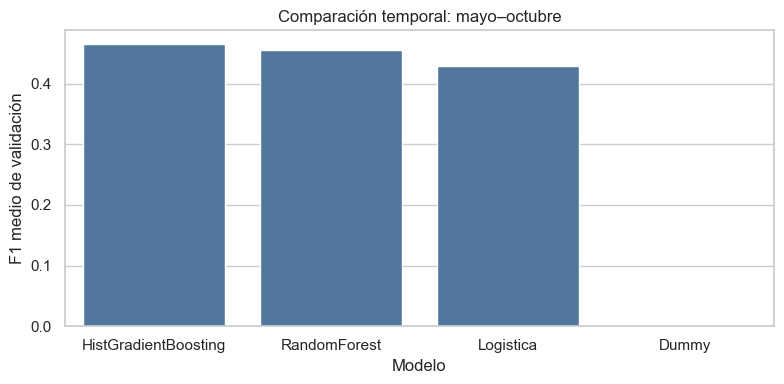

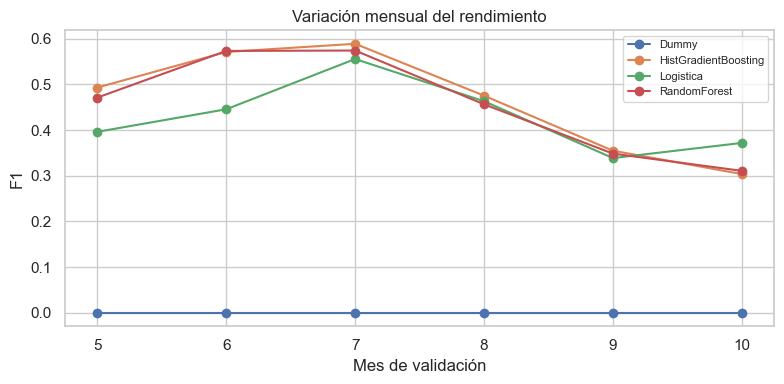

In [7]:
plt.figure(figsize=(8, 4))
sns.barplot(data=comparacion, x='modelo', y='f1', color='#4477AA')
plt.ylabel('F1 medio de validación')
plt.xlabel('Modelo')
plt.title('Comparación temporal: mayo–octubre')
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 4))
for nombre, tabla in cv.groupby('modelo'):
    plt.plot(tabla['mes'], tabla['f1'], marker='o', label=nombre)
plt.xlabel('Mes de validación')
plt.ylabel('F1')
plt.title('Variación mensual del rendimiento')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


Un modelo puede tener buena accuracy y F1 bajo si predice la clase mayoritaria. Las diferencias entre meses no demuestran una causa y las ventanas comparten historial de entrenamiento.

## 6. Ajustes finales y evaluación posterior en noviembre
Se reentrenan las cuatro configuraciones con enero–octubre elegible según los mismos márgenes. Se evalúa noviembre una vez por configuración. El ganador y el umbral ya están fijados y no se modifican a partir de esta tabla.


In [8]:
train_final, noviembre = separar_mes(etiquetados, 11)
predicciones = noviembre[['id_vuelo', 'year', 'month', 'day', 'carrier', 'origin', 'dest', 'hour']].copy()
predicciones['y_real'] = noviembre[TARGET_COL].to_numpy()
resultados_noviembre = []
for config in configuraciones:
    pipe = crear_pipeline(config)
    inicio = time.perf_counter()
    with warnings.catch_warnings(), threadpool_limits(limits=HILOS):
        warnings.simplefilter('error', ConvergenceWarning)
        pipe.fit(train_final[FEATURES_B], train_final[TARGET_COL])
    segundos = time.perf_counter() - inicio
    assert np.array_equal(pipe.named_steps['modelo'].classes_, [0, 1])
    with threadpool_limits(limits=HILOS):
        prob = pipe.predict_proba(noviembre[FEATURES_B])[:, 1]
    predicciones['prob_' + config['id']] = prob
    predicciones['pred_' + config['id']] = (prob >= UMBRAL).astype(int)
    resultados_noviembre.append({'id': config['id'], 'modelo': config['modelo'],
        'n_train': len(train_final), 'n_noviembre': len(noviembre), 'segundos_fit': segundos,
        **calcular_metricas(noviembre[TARGET_COL], prob, umbral=UMBRAL)})
metricas_noviembre = pd.DataFrame(resultados_noviembre)
display(metricas_noviembre.round(4))


C:\Users\Rodrigo D SantaMaria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,id,modelo,n_train,n_noviembre,segundos_fit,accuracy,precision,recall,f1,roc_auc,average_precision
0,dummy,Dummy,270513,26971,2.3281,0.8190,0.0000,0.0000,0.0000,0.5000,0.1810
1,logistica,Logistica,270513,26971,8.2327,0.7612,0.3543,0.3884,0.3705,0.6731,0.3521
2,bosque,RandomForest,270513,26971,22.9456,0.7646,0.3550,0.3675,0.3611,0.6750,0.3378
3,boosting,HistGradientBoosting,270513,26971,9.6117,0.7800,0.3727,0.3154,0.3417,0.6684,0.3448


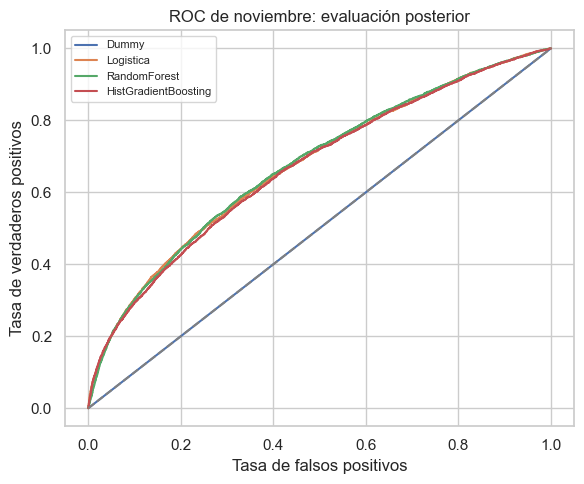

In [9]:
plt.figure(figsize=(6, 5))
for config in configuraciones:
    fpr, tpr, _ = roc_curve(predicciones['y_real'], predicciones['prob_' + config['id']])
    plt.plot(fpr, tpr, label=config['modelo'])
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('ROC de noviembre: evaluación posterior')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


El gráfico de noviembre describe la evaluación posterior, sin volver a seleccionar modelos. Un orden diferente de familias no sustituye al ganador elegido en desarrollo.

## 7. Resultados reproducibles para el análisis de errores
Cada ejecución crea una carpeta nueva en `outputs/entrega_actual/`. Se guardan las métricas recién calculadas, las probabilidades, las predicciones y el protocolo. Un índice identifica la última ejecución terminada; las carpetas anteriores y los resultados históricos se conservan.


In [10]:
ejecucion = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
salidas = raiz / 'outputs' / 'entrega_actual'
carpeta = salidas / ejecucion
carpeta.mkdir(parents=True, exist_ok=False)
cv.to_csv(carpeta / 'validacion_temporal.csv', index=False)
comparacion.to_csv(carpeta / 'comparacion_modelos.csv', index=False)
metricas_noviembre.to_csv(carpeta / 'metricas_noviembre.csv', index=False)
predicciones.to_csv(carpeta / 'predicciones_noviembre.csv', index=False)
protocolo = {'ejecucion': ejecucion, 'modelo_seleccionado': ganador_id,
    'nombre_modelo': ganador_nombre, 'semilla': SEED, 'umbral': UMBRAL,
    'variables': FEATURES_B, 'configuraciones': configuraciones,
    'meses_validacion': MESES_VALIDACION, 'embargo_horas': MARGEN_HORAS,
    'margen_etiqueta_horas': 24, 'horizonte_prediccion_horas': 2,
    'n_train_final': len(train_final), 'n_noviembre': len(noviembre), 'n_ajustes': len(cv) + len(metricas_noviembre),
    'noviembre_previamente_consultado': True, 'disponibilidad_clima_verificada': False,
    'versiones': {p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'nycflights13']}}
(carpeta / 'protocolo.json').write_text(json.dumps(protocolo, indent=2, ensure_ascii=False), encoding='utf-8')
(salidas / 'ultima_ejecucion.json').write_text(json.dumps({'ejecucion': ejecucion}), encoding='utf-8')
print('Resultados de esta ejecución:', carpeta.relative_to(raiz))


Resultados de esta ejecución: outputs\entrega_actual\20261027T151138_544528Z


In [11]:
elegido = metricas_noviembre.set_index('id').loc[ganador_id]
display(Markdown(f"**Resultado:** {ganador_nombre} fue seleccionado por F1 medio de desarrollo "
    f"{comparacion.iloc[0]['f1']:.4f}. En noviembre obtuvo F1 {elegido['f1']:.4f} y "
    f"ROC-AUC {elegido['roc_auc']:.4f}. Los {len(cv) + len(metricas_noviembre)} ajustes se ejecutaron en este notebook."))


**Resultado:** HistGradientBoosting fue seleccionado por F1 medio de desarrollo 0.4646. En noviembre obtuvo F1 0.3417 y ROC-AUC 0.6684. Los 28 ajustes se ejecutaron en este notebook.

## 8. Conclusión y limitaciones
La comparación incluye una referencia trivial y tres familias aprendidas con las mismas observaciones. El análisis de errores utiliza exclusivamente las predicciones generadas por esta ejecución.

El clima y la disponibilidad de etiquetas siguen siendo estimados; las versiones históricas de horarios no están verificadas. Los atributos de aeronaves se excluyen por calidad y disponibilidad, y las etiquetas desconocidas pueden introducir sesgo. Un único año de NYC limita la generalización. Las decisiones previas y la consulta anterior de noviembre impiden considerarlo una evaluación completamente virgen. El test de diciembre se expuso en el primer avance y no se utiliza aquí. No se ajustan umbrales, calibración ni parámetros a partir de noviembre.
